## Benutils vs. PyTorch

### Question 
The purpose of this investigation is to understand and compare specific differences between my scratch network training engine, benutils, and the common open-source ML framework, PyTorch, under controlled conditions.

### Methodology
This investigation will be centered around training 2 neural network models on [Boston Housing](https://www.kaggle.com/code/prasadperera/the-boston-housing-dataset), a legacy testing dataset.

[The imported  dataset](https://www.kaggle.com/datasets/vikrishnan/boston-house-prices/data), is readily available to our models within this folder. It serves as a benchmark for model performance comparisons. I chose this established testing because of a history of consistent rigourous testing, evaluations, and familiarity that will help isolate variables for comparisons. 

For running and displaying output from benutils, the vanilla JavaScript library, I will utilize a Python subprocess and node.js.

##### Architecture
This investigation will compare performances for all 3 of benutils' basic architecture types: flat, power of two, and hourglass. Hourglass architecture will be using it's default operator, "/", leading to the standard contract-to-center into expanion-to-end shape that is associated with the hourglass name. 

However, before getting into full tests, I will create an extremely simple 2->2->1 model and manually match the weights of both to test basic functionality and math implementation.

In [ ]:
%%script node

import {neuralnet, set_features} from "../src/network.js";

const model = neuralnet({
    hidden_layer_info: {
        count:1, 
        init_size:2, 
        style:"flat"
    },
    activation_type:"relu",
    learn_rate:.01,
    output_layer_info:{
        init_size:1, 
        activation:"none"
    },
    epochs:1,
    tt_split:0,
    random_seed:33463,
    batch_size:1
});

const features_in = {
    "feat1":[3.0, 12.0, 25.0],
    "feat2":[5.0, 15.0, 35.0],
    "TARGET":[22.0, 40.0, 11.0]
}

//Set features, but dont shuffle the values
model.set_features(features_in, false);

model.train();

console.log("\n\n BENUTILS POST TRAINING UPDATED WEIGHTS:")

/* "A SECOND COPY OF THIS LOGGIN PROCEDURE WAS TEMPORARILY PLACED IN model.train() to log initial weight and bias values."
    "Thankfully, due to seeding, it stays consistent. Initial output is saved as the first output of this cell"*/
console.log("--input_layer--","\nvalues:", model.layers["input_layer"]["output"]);
console.log();
console.log("--hidden_layer_1--", "weights:", model.layers["hidden_layer_1"]["main"]["weights"], "\nbiases:", model.layers["hidden_layer_1"]["main"]["biases"], "\nvalues:", model.layers["hidden_layer_1"]["output"]);
console.log();
console.log("--output_layer--", "\nweights:", model.layers["output_layer"]["main"]["weights"], "\nbiases:", model.layers["output_layer"]["main"]["biases"], "\nvalues:", model.layers["output_layer"]["output"]);



now buidling model[SEED: 33463]
1 epochs
0 train/test split
relu activation
1 batch size
flat architecture, hg_oper?: /
0.01 learning rate
--input_layer-- 
values: []

--hidden_layer_1-- weights: [
  [ 0.5110150227328565, 1.2756492915094295 ],
  [ -0.5771150797856148, 0.6096600024628742 ]
] 
biases: [ 0, 0 ] 
values: []

--output_layer-- 
weights: [ [ 1.292116896082979, -0.41084944789670486 ] ] 
biases: [ 0 ] 
values: []


 BENUTILS POST TRAINING UPDATED WEIGHTS:
--input_layer-- 
values: [ 25, 35 ]

--hidden_layer_1-- weights: [
  [ -14.734454171092503, -17.582221280030623 ],
  [ -0.7289497113452345, 0.35660228319684145 ]
] 
biases: [ -1.1510762137071242, -0.05061154385320655 ] 
values: [ 0, 0 ]

--output_layer-- 
weights: [ [ -22.643741723699275, -0.2486169936839701 ] ] 
biases: [ -0.3403090035059921 ] 
values: [ -0.4548575792989819 ]


Matching that parameter initialization in PyTorch:

In [326]:
import torch
import numpy as np
import pandas as pd

class Network(torch.nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.input_layer = torch.nn.Linear(in_features=input_dim, out_features=2)
        self.hidden_layer = torch.nn.Linear(2, 1)

    def forward(self, x):
        x = torch.relu(self.input_layer(x))
        x = self.hidden_layer(x)
        return x

#MANUALLY MATCHING PARAMETER VALUES TO BENUTILS RUN
simple_input = torch.tensor([[3.0, 5.0], [12.0, 15.0], [25.0, 35.0]])
simple_targets = torch.tensor([[22.0], [40.0], [11.0]])

# 2 feature input layer
model = Network(input_dim=2)

custom_input_weights = torch.tensor(
    [[ 0.5110150227328565, 1.2756492915094295 ],
    [-0.5771150797856148, 0.6096600024628742]]
)

custom_output_weights = torch.tensor(
    [[ 1.292116896082979, -0.41084944789670486 ]]
)

with torch.no_grad():
    model.input_layer.weight.copy_(custom_input_weights)
    model.input_layer.bias.fill_(0)

    model.hidden_layer.weight.copy_(custom_output_weights)
    model.hidden_layer.bias.fill_(0)

weights_dict = model.state_dict()

for key in weights_dict.keys():
    print(key, weights_dict[key])

input_layer.weight tensor([[ 0.5110,  1.2756],
        [-0.5771,  0.6097]])
input_layer.bias tensor([0., 0.])
hidden_layer.weight tensor([[ 1.2921, -0.4108]])
hidden_layer.bias tensor([0.])


Now that our initial parameters are matching, we must a design difference that makes running a seemingly equivalent PyTorch training procedure yield different results.

PyTorch's mean squared error loss equation uses the pure mathmatical definition of MSE, without the 1/2 scaler that is commonly used to simplify the process of calculating loss. In practice, this only affects the scale of the delta values, which means we can easily account for it without ruining either implementation.

Lets see the parameters after training through 1 epoch of our simple example data, accounting for PyTorch's gradient equation by multiplying it's loss calculations by 0.5:

In [327]:
criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Loop to mimic benutils batch_size: 1 behavior
for i in range(len(simple_input)):
    optimizer.zero_grad()
    
    # Take one sample at a time with a batch of 1
    single_input = simple_input[i].unsqueeze(0)
    single_target = simple_targets[i].unsqueeze(0)
    
    predictions = model(single_input)
    loss = 0.5 * criterion(predictions, single_target) # Accounting for pure MSE calculation
    
    loss.backward()
    optimizer.step()

print("PYTORCH POST-TRAINING UPDATED WEIGHTS:")

weights_dict = model.state_dict()
for key in weights_dict.keys():
    print("\n", key, weights_dict[key])

print("\noutput: ", predictions[0])

PYTORCH POST-TRAINING UPDATED WEIGHTS:

 input_layer.weight tensor([[-14.7345, -17.5822],
        [ -0.7289,   0.3566]])

 input_layer.bias tensor([-1.1511, -0.0506])

 hidden_layer.weight tensor([[-22.6437,  -0.2486]])

 hidden_layer.bias tensor([-0.3403])

output:  tensor([-0.4549], grad_fn=<SelectBackward0>)


##### We can now see that the parameter values between the models are matching! This confirms that benutils' training, at least within this test-case, was implemented correctly and allows us to move on to comparing their behavior involving larger architecture.
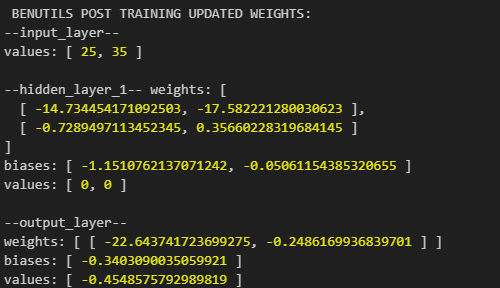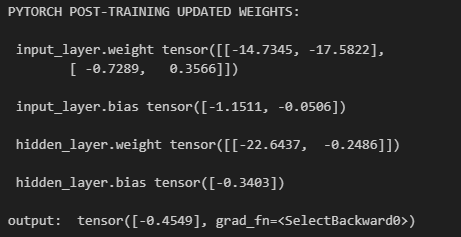

## Phase 2: Full Architecture Performance Comparison

##### First, we will compare the models on the benutils "flat" architecture:

Since our unit-test was successful, we no longer need to match parameter initializations 1:1 between the models. Since this experiment is meant to highlight the differences between the engine implementation, it seems most reasonable to compare them with their native implementations. This change will include removing the forced loss scaler from phase 1, as it is no longer needed.

benutils:

In [ ]:
%%script node

import {neuralnet, set_features, set_features_csv, normalize_features} from "../src/network.js";

const model = neuralnet({
    hidden_layer_info: {
        count:1, 
        init_size:2, 
        style:"flat"
    },
    activation_type:"relu",
    learn_rate:.01,
    output_layer_info:{
        init_size:1, 
        activation:"none"
    },
    epochs:1,
    tt_split:0,
    random_seed:33463,
    batch_size:1
});

const features_in = {
    "feat1":[3.0, 12.0, 25.0],
    "feat2":[5.0, 15.0, 35.0],
    "TARGET":[22.0, 40.0, 11.0]
}

//Set features, but dont shuffle the values
model.set_features(features_in, false);

model.train();

console.log("\n\n BENUTILS POST TRAINING UPDATED WEIGHTS:")

/* "A SECOND COPY OF THIS LOGGIN PROCEDURE WAS TEMPORARILY PLACED IN model.train() to log initial weight and bias values."
    "Thankfully, due to seeding, it stays consistent. Initial output is saved as the first output of this cell"*/
console.log("--input_layer--","\nvalues:", model.layers["input_layer"]["output"]);
console.log();
console.log("--hidden_layer_1--", "weights:", model.layers["hidden_layer_1"]["main"]["weights"], "\nbiases:", model.layers["hidden_layer_1"]["main"]["biases"], "\nvalues:", model.layers["hidden_layer_1"]["output"]);
console.log();
console.log("--output_layer--", "\nweights:", model.layers["output_layer"]["main"]["weights"], "\nbiases:", model.layers["output_layer"]["main"]["biases"], "\nvalues:", model.layers["output_layer"]["output"]);

